# 02 – Federated Learning mit IID-Daten (Task 2)

Dasselbe MLP wie in Notebook 01 wird jetzt föderiert trainiert (Flower, FedAvg). Die Trainingsdaten werden **gleichmäßig und stratifiziert** auf die Clients verteilt (IID).

Fragen:
1. Erreicht FL die zentrale Baseline (Test-Accuracy 0.855)?
2. Wie wirkt sich die Anzahl der Clients aus (2, 5, 10, 20)?
3. Welche Hyperparameter (lokale Epochen, Batchgröße, Lernrate, Anteil Clients pro Runde) helfen?
4. Ist FL besser als die lokalen Baselines?

**Ablauf einer Runde:** Server schickt globales Modell → jeder Client trainiert `E` lokale Epochen auf 85 % seiner Daten → Server bildet den gewichteten Mittelwert (FedAvg) → Auswertung des globalen Modells auf Val- und Testset.

**Methodik:** Hyperparameter werden auf dem **Validierungsset** gewählt, das Testset dient nur dem finalen Vergleich. Runde 0 = zufällig initialisiertes Startmodell.

Jeder Lauf läuft in einem eigenen Python-Prozess (`fl.run_cached`) und wird in `results/02/` gespeichert (Metriken als CSV, finales Modell als .pt). Beim erneuten Ausführen werden fertige Läufe geladen statt neu gerechnet (`FORCE = True` erzwingt Neuberechnung). Der eigene Prozess schützt den Notebook-Kernel vor einem Absturz von Ray beim Herunterfahren, der unter Windows auftreten kann.

In [19]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fl import run_cached

ROUNDS = 30
SEEDS = [42, 43, 44]
FORCE = False
OUT = Path("results/02"); OUT.mkdir(parents=True, exist_ok=True)

base = json.loads(Path("results/01_baselines.json").read_text())
CENTRAL_ACC = base["central"]["mean"]["accuracy"]
CENTRAL_F1 = base["central"]["mean"]["f1"]
LOCAL = {k: v["mean"] for k, v in base["local"].items()}
print(f"Zentral: Acc {CENTRAL_ACC:.4f}, F1 {CENTRAL_F1:.4f}")


def run(name, **kw):
    """FL-Lauf mit Cache (results/02/<name>.csv). Läuft in eigenem Prozess, siehe fl.run_cached."""
    return run_cached(OUT / f"{name}.csv", force=FORCE, **kw)


def last(h, col="test_accuracy", k=1):
    """Mittel über die letzten k Runden."""
    return h[col].iloc[-k:].mean()

Zentral: Acc 0.8546, F1 0.6595


## 1. Anzahl der Clients

Feste Einstellung wie im zentralen Training: Adam, Lernrate 0.001, Batchgröße 64, **1 lokale Epoche pro Runde**, alle Clients nehmen an jeder Runde teil.

In [20]:
N_CLIENTS = [2, 5, 10, 20]
runs_n = {n: run(f"iid_n{n}_E1", partition="iid", n_clients=n, num_rounds=ROUNDS, local_epochs=1)
          for n in N_CLIENTS}

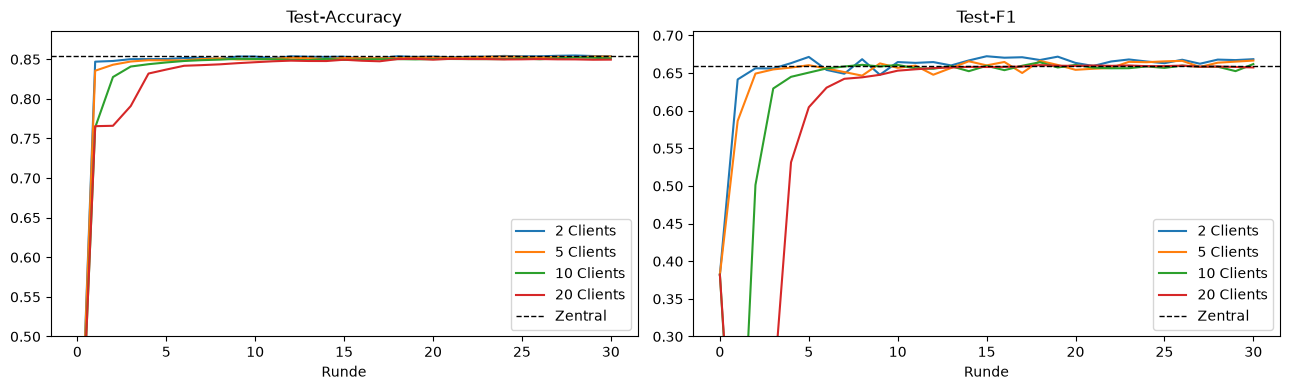

,Test-Acc (letzte Runde),Test-F1,Lokal (Acc),Laufzeit [s]
2,0.8539,0.6684,0.8509,70.3
5,0.8535,0.6666,0.8465,72.6
10,0.8511,0.6619,0.8445,78.5
20,0.8496,0.6574,0.8398,86.8


In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for n, h in runs_n.items():
    ax[0].plot(h["round"], h.test_accuracy, label=f"{n} Clients")
    ax[1].plot(h["round"], h.test_f1, label=f"{n} Clients")
for a, c, t in [(ax[0], CENTRAL_ACC, "Test-Accuracy"), (ax[1], CENTRAL_F1, "Test-F1")]:
    a.axhline(c, color="k", ls="--", lw=1, label="Zentral")
    a.set(title=t, xlabel="Runde", ylim=(0.5 if "Acc" in t else 0.3, None)); a.legend()
plt.tight_layout(); plt.savefig(OUT / "clients_curves.png", dpi=150); plt.show()

pd.DataFrame({n: {"Test-Acc (letzte Runde)": last(h), "Test-F1": last(h, "test_f1"),
                  "Lokal (Acc)": LOCAL.get(f"IID, {n} Clients", {}).get("accuracy"),
                  "Laufzeit [s]": h.runtime_s.iloc[0]} for n, h in runs_n.items()}).T.round(4)

Mit mehr Clients hat jeder Client weniger Daten. Bei 1 lokaler Epoche macht jeder Client pro Runde entsprechend weniger Optimierungsschritte, das globale Modell lernt pro Runde langsamer. Der nächste Abschnitt prüft, ob mehr lokale Berechnung das ausgleicht.

## 2. Hyperparameter (10 Clients)

Ausgehend von der Grundeinstellung wird jeweils **ein** Parameter verändert. Auswahlkriterium: mittlere **Val-Accuracy der letzten 5 Runden**.

| Parameter | Werte |
|---|---|
| lokale Epochen E | 1, 2, 5 |
| Batchgröße B | 32, 64, 128 |
| Lernrate | 0.0003, 0.001, 0.003 |
| Anteil Clients pro Runde | 0.5, 1.0 |

In [22]:
N = 10
grid = {
    "E1 (Basis)": dict(local_epochs=1),
    "E2": dict(local_epochs=2),
    "E5": dict(local_epochs=5),
    "B32": dict(batch_size=32),
    "B128": dict(batch_size=128),
    "lr0.0003": dict(lr=3e-4),
    "lr0.003": dict(lr=3e-3),
    "50% Clients/Runde": dict(fraction_train=0.5),
}
runs_hp = {}
for name, kw in grid.items():
    fname = "iid_n10_" + name.split(" ")[0].replace("%", "pct").replace("/", "")
    runs_hp[name] = (runs_n[N] if name == "E1 (Basis)"
                     else run(fname, partition="iid", n_clients=N, num_rounds=ROUNDS, **kw))

hp = pd.DataFrame({name: {"Val-Acc (letzte 5)": last(h, "val_accuracy", 5),
                          "Test-Acc (letzte)": last(h), "Test-F1 (letzte)": last(h, "test_f1"),
                          "Max Val-Acc": h.val_accuracy.max(),
                          "Runde Max": int(h.loc[h.val_accuracy.idxmax(), "round"])}
                   for name, h in runs_hp.items()}).T
hp.sort_values("Val-Acc (letzte 5)", ascending=False).round(4)

,Val-Acc (letzte 5),Test-Acc (letzte),Test-F1 (letzte),Max Val-Acc,Runde Max
E5,0.8587,0.8515,0.6542,0.8596,30.0
E2,0.8572,0.8535,0.6627,0.8579,22.0
B32,0.8567,0.8525,0.6598,0.8579,30.0
lr0.003,0.8562,0.8527,0.6603,0.8583,20.0
E1 (Basis),0.8558,0.8511,0.6619,0.8567,27.0
50% Clients/Runde,0.8553,0.8511,0.6590,0.8565,30.0
B128,0.8537,0.8496,0.6618,0.8549,25.0
lr0.0003,0.8506,0.8499,0.6588,0.8514,29.0


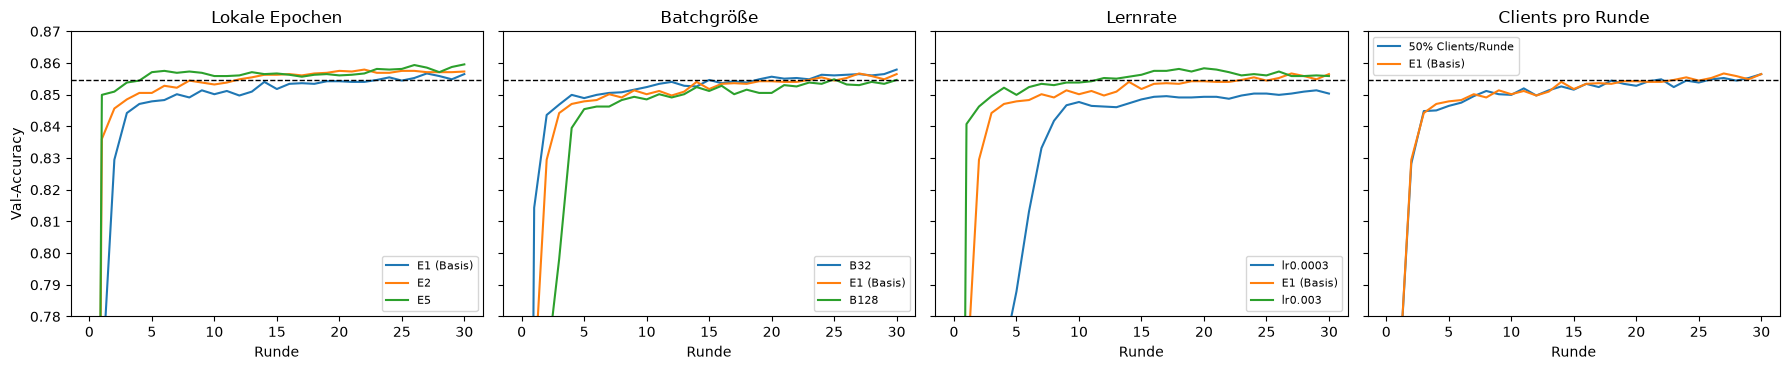

In [23]:
groups = {"Lokale Epochen": ["E1 (Basis)", "E2", "E5"],
          "Batchgröße": ["B32", "E1 (Basis)", "B128"],
          "Lernrate": ["lr0.0003", "E1 (Basis)", "lr0.003"],
          "Clients pro Runde": ["50% Clients/Runde", "E1 (Basis)"]}
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for a, (title, names) in zip(ax, groups.items()):
    for nme in names:
        a.plot(runs_hp[nme]["round"], runs_hp[nme].val_accuracy, label=nme)
    a.axhline(CENTRAL_ACC, color="k", ls="--", lw=1)
    a.set(title=title, xlabel="Runde", ylim=(0.78, 0.87)); a.legend(fontsize=8)
ax[0].set_ylabel("Val-Accuracy")
plt.tight_layout(); plt.savefig(OUT / "hyperparams.png", dpi=150); plt.show()

## 3. Beste Einstellung für alle Clientzahlen, 3 Seeds

Die auf dem Validierungsset beste Einstellung wird für 2, 5, 10 und 20 Clients mit drei Seeds wiederholt (Seed = Modellinitialisierung und Reihenfolge im lokalen Training; die Partition bleibt gleich).

In [24]:
best_name = hp["Val-Acc (letzte 5)"].idxmax()
best_kw = grid[best_name]
print("Beste Einstellung:", best_name, best_kw)

final = []
curves = {}
for n in N_CLIENTS:
    for s in SEEDS:
        tag = "_".join(f"{k}{v}" for k, v in best_kw.items())
        h = run(f"iid_n{n}_best_{tag}_s{s}", partition="iid", n_clients=n,
                num_rounds=ROUNDS, seed=s, **best_kw)
        curves[(n, s)] = h
        final.append({"n_clients": n, "seed": s, "test_acc": last(h), "test_f1": last(h, "test_f1"),
                      "test_auc": last(h, "test_roc_auc"), "test_bal_acc": last(h, "test_balanced_acc")})
final = pd.DataFrame(final)

Beste Einstellung: E5 {'local_epochs': 5}


In [25]:
def rounds_to(h, target, col="val_accuracy"):
    hit = h.loc[h[col] >= target, "round"]
    return int(hit.iloc[0]) if len(hit) else np.nan

summary = final.groupby("n_clients").agg(
    FL_acc=("test_acc", "mean"), FL_acc_std=("test_acc", "std"),
    FL_f1=("test_f1", "mean"), FL_auc=("test_auc", "mean"))
summary["Zentral_acc"] = CENTRAL_ACC
summary["Lokal_acc"] = [LOCAL[f"IID, {n} Clients"]["accuracy"] for n in summary.index]
summary["Lokal_f1"] = [LOCAL[f"IID, {n} Clients"]["f1"] for n in summary.index]
TARGET = 0.855  # Niveau des zentralen Modells
summary[f"Runden bis Val-Acc ≥ {TARGET}"] = [
    np.nanmean([rounds_to(curves[(n, s)], TARGET) for s in SEEDS]) for n in summary.index]
summary.round(4)

,FL_acc,FL_acc_std,FL_f1,FL_auc,Zentral_acc,Lokal_acc,Lokal_f1,Runden bis Val-Acc ≥ 0.855
n_clients,,,,,,,,
2,0.8484,0.0015,0.6468,0.8929,0.8546,0.8509,0.6520,1.6667
5,0.8498,0.0011,0.6552,0.8996,0.8546,0.8465,0.6538,2.3333
10,0.8498,0.0021,0.6563,0.9000,0.8546,0.8445,0.6460,4.3333
20,0.8499,0.0015,0.6613,0.9003,0.8546,0.8398,0.6401,9.0000


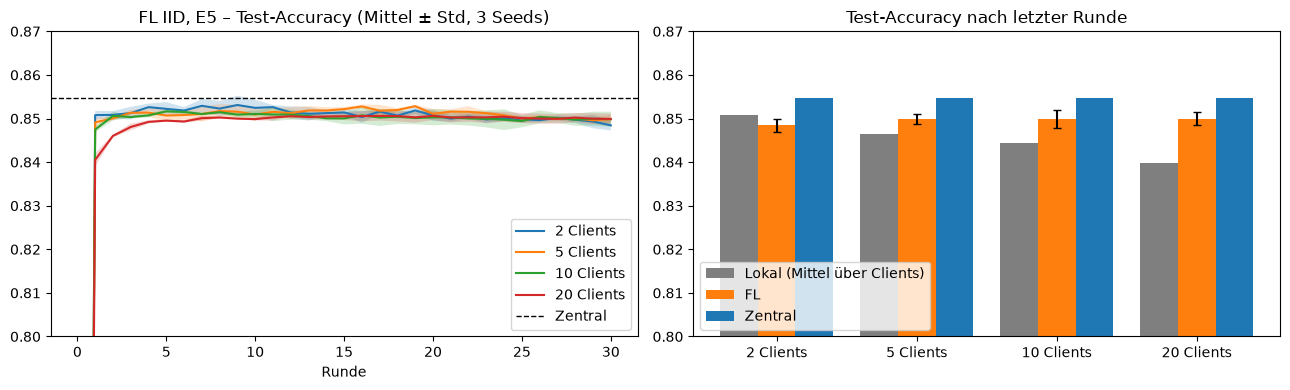

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for n in N_CLIENTS:
    acc = np.stack([curves[(n, s)].test_accuracy.to_numpy() for s in SEEDS])
    r = curves[(n, SEEDS[0])]["round"]
    ax[0].plot(r, acc.mean(0), label=f"{n} Clients")
    ax[0].fill_between(r, acc.mean(0) - acc.std(0), acc.mean(0) + acc.std(0), alpha=0.2)
ax[0].axhline(CENTRAL_ACC, color="k", ls="--", lw=1, label="Zentral")
ax[0].set(title=f"FL IID, {best_name} – Test-Accuracy (Mittel ± Std, 3 Seeds)", xlabel="Runde", ylim=(0.8, 0.87))
ax[0].legend()

x = np.arange(len(summary)); w = 0.27
ax[1].bar(x - w, summary.Lokal_acc, w, label="Lokal (Mittel über Clients)", color="tab:gray")
ax[1].bar(x, summary.FL_acc, w, yerr=summary.FL_acc_std, label="FL", color="tab:orange", capsize=3)
ax[1].bar(x + w, summary.Zentral_acc, w, label="Zentral", color="tab:blue")
ax[1].set(xticks=x, xticklabels=[f"{n} Clients" for n in summary.index], ylim=(0.8, 0.87),
          title="Test-Accuracy nach letzter Runde")
ax[1].legend(loc="lower left")
plt.tight_layout(); plt.savefig(OUT / "iid_summary.png", dpi=150); plt.show()

In [27]:
(OUT / "summary.json").write_text(json.dumps({
    "best_config": {"name": best_name, **best_kw, "rounds": ROUNDS, "seeds": SEEDS},
    "hyperparams": hp.to_dict(orient="index"),
    "summary": summary.reset_index().to_dict(orient="records"),
}, indent=2, default=float))
print("gespeichert:", OUT / "summary.json")

gespeichert: results\02\summary.json


## 4. Mehr lokale Epochen: weniger Runden, aber Overfitting bei wenigen Clients

Vergleich 1 vs. 5 lokale Epochen (E1: ein Seed, E5: Mittel über 3 Seeds). Links die Test-Accuracy, rechts der mittlere Trainings-Loss der Clients.

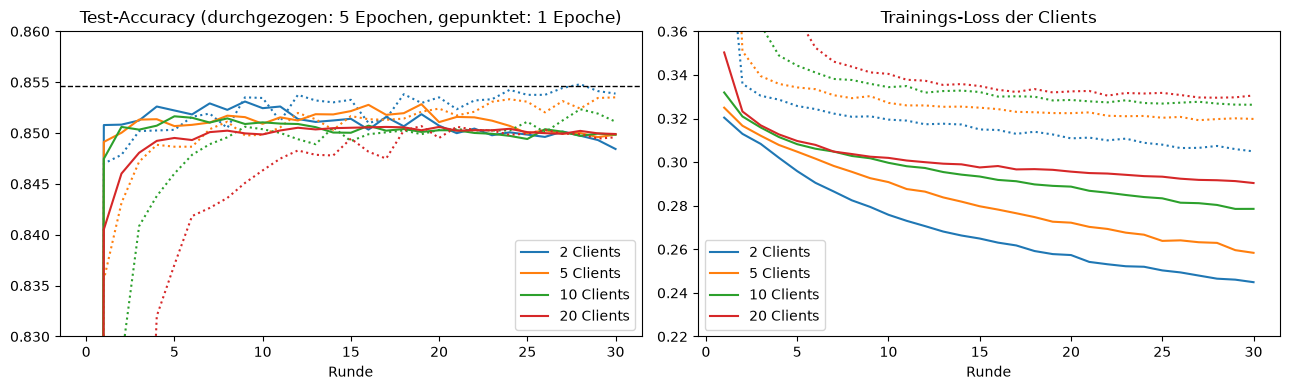

,Runden bis Val ≥ 0.855 (E1),Runden bis Val ≥ 0.855 (E5),Test-Acc E1 (Runde 30),Test-Acc E5 (Runde 30),Test-Acc E5 max (Runde)
Clients,,,,,
2,7.0,1.6667,0.8539,0.8484,0.8531 (9)
5,13.0,2.3333,0.8535,0.8498,0.8528 (19)
10,24.0,4.3333,0.8511,0.8498,0.8516 (5)
20,NaN,9.0000,0.8496,0.8499,0.8506 (17)


In [28]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
colors = dict(zip(N_CLIENTS, ["tab:blue", "tab:orange", "tab:green", "tab:red"]))
for n in N_CLIENTS:
    e1 = runs_n[n]
    e5 = pd.concat([curves[(n, s)] for s in SEEDS]).groupby("round").mean(numeric_only=True).reset_index()
    ax[0].plot(e1["round"], e1.test_accuracy, ls=":", color=colors[n])
    ax[0].plot(e5["round"], e5.test_accuracy, color=colors[n], label=f"{n} Clients")
    ax[1].plot(e1["round"], e1.clients_train_loss, ls=":", color=colors[n])
    ax[1].plot(e5["round"], e5.clients_train_loss, color=colors[n], label=f"{n} Clients")
ax[0].axhline(CENTRAL_ACC, color="k", ls="--", lw=1)
ax[0].set(title="Test-Accuracy (durchgezogen: 5 Epochen, gepunktet: 1 Epoche)", xlabel="Runde", ylim=(0.83, 0.86))
ax[1].set(title="Trainings-Loss der Clients", xlabel="Runde", ylim=(0.22, 0.36))
ax[0].legend(); ax[1].legend()
plt.tight_layout(); plt.savefig(OUT / "epochs_overfitting.png", dpi=150); plt.show()

rows = []
for n in N_CLIENTS:
    e5 = pd.concat([curves[(n, s)] for s in SEEDS]).groupby("round").mean(numeric_only=True)
    rows.append({"Clients": n,
                 "Runden bis Val ≥ 0.855 (E1)": rounds_to(runs_n[n], TARGET),
                 "Runden bis Val ≥ 0.855 (E5)": np.nanmean([rounds_to(curves[(n, s)], TARGET) for s in SEEDS]),
                 "Test-Acc E1 (Runde 30)": runs_n[n].test_accuracy.iloc[-1],
                 "Test-Acc E5 (Runde 30)": e5.test_accuracy.iloc[-1],
                 "Test-Acc E5 max (Runde)": f"{e5.test_accuracy.max():.4f} ({int(e5.test_accuracy.idxmax())})"})
pd.DataFrame(rows).set_index("Clients").round(4)

## Beobachtungen

Zahlen aus unserem Lauf (Windows, Python 3.12, flwr 1.45, 27.11.2026).

- **FL erreicht fast die zentrale Baseline (0.855).** Mit 1 lokalen Epoche liegt die Test-Accuracy nach 30 Runden bei 0.854 (2 und 5 Clients), 0.851 (10) und 0.850 (20). Mit der auf Val gewählten Einstellung (5 lokale Epochen) sind es 0.848–0.850 (3 Seeds, Streuung ±0,1–0,2). F1 liegt bei 0.65–0.66 wie zentral.
- **FL schlägt die lokalen Modelle ab 5 Clients,** und der Vorsprung wächst mit der Clientzahl: +0,3 Prozentpunkte bei 5 Clients, +0,5 bei 10, +1,0 bei 20. Je kleiner der Datenanteil pro Client, desto mehr bringt die Zusammenarbeit. Bei IID-Daten bleibt der Gewinn trotzdem klein, weil schon ein Zwanzigstel des Datensatzes für ein brauchbares Modell reicht.
- **Mehr Clients kosten vor allem Runden.** Bis die Val-Accuracy 0.855 erreicht, braucht FedAvg mit 1 lokalen Epoche 7 (2 Clients), 13 (5), 24 (10) Runden; mit 20 Clients wird der Wert in 30 Runden nicht erreicht.
- **Mehr lokale Epochen sparen Kommunikation.** Mit 5 statt 1 lokalen Epoche sinkt die Rundenzahl auf etwa 2, 2, 4 und 9. Jeder Client rechnet mehr pro Runde, dafür werden viel weniger Modelle übertragen.
- **Aber: 5 Epochen führen zu Overfitting.** Mit 5 Epochen sinkt der Trainings-Loss der Clients viel tiefer (2 Clients: 0.245 gegenüber 0.305), die Test-Accuracy aber nicht mit: Bei 2 Clients liegt das Maximum (0.853) schon in Runde 9, danach fällt sie auf 0.848. Am Ende der 30 Runden ist 1 Epoche bei 2, 5 und 10 Clients besser (0.854 / 0.854 / 0.851) als 5 Epochen (0.848 / 0.850 / 0.850). Nur bei 20 Clients, wo jeder Client wenig Daten hat, sind beide gleich. Die Auswahl auf dem Validierungsset (bei 10 Clients) hat das nicht erkannt, weil die Unterschiede auf Val im Rauschen liegen. Abhilfe: Early Stopping über die Runden oder 5 Epochen nur für die ersten Runden, danach weniger (wie in der Vorlesung empfohlen: lokale Berechnung reduzieren, wenn das Modell konvergiert).
- **Hyperparameter haben bei IID nur kleine Effekte.** Val-Accuracy aller Varianten zwischen 0.851 und 0.859. Nur die kleine Lernrate 0.0003 fällt deutlich ab. Halbe Teilnahme pro Runde (50 % der Clients) ergibt praktisch dasselbe Ergebnis.
- **Val- und Test-Accuracy unterscheiden sich systematisch** um etwa 0,5–1 Prozentpunkt (Val höher). Das Validierungsset stammt aus `adult.data`, das Testset ist die separate Datei `adult.test`. Deshalb vergleichen wir mit der zentralen Baseline nur auf dem Testset.
- **Technik:** Unter Windows stürzt Ray beim Herunterfahren mit „access violation“ ab. Die Ergebnisse werden deshalb vor dem Herunterfahren gespeichert, und jeder Lauf läuft in einem eigenen Prozess (`fl.run_cached`). Ein Lauf mit 30 Runden dauert unter Windows 70–90 s.